# Arabic Narrative QA with mT5-Large Full Context

This notebook implements a transformer encoder-decoder pipeline for Arabic narrative question answering using full context inputs. It includes data loading, preprocessing, train-validation-test splitting, baseline evaluation, full fine-tuning, validation loss tracking, test inference, metric computation, visualizations, and comparative analysis.

## Methodology overview

The system uses `google/mt5-large`, a transformer-based encoder-decoder model. The encoder receives the Arabic instruction, question, and full context. The decoder generates the Arabic answer autoregressively. Fine-tuning updates the model on the supervised QA dataset, while validation loss monitors training progress. Final metrics are computed only on the held-out test set.

In [1]:
# import packages

import os
import re
import gc
import json
import random
import math
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import sacrebleu
import matplotlib.pyplot as plt

from datasets import Dataset
from tqdm import tqdm
from bert_score import score as bertScore
from sentence_transformers import SentenceTransformer, util
from rouge_score import rouge_scorer

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    set_seed
)

seed = 3407
set_seed(seed)
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("device:", device)
print("torch:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("gpu:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

device: cuda
torch: 2.5.1+cu121
cuda available: True
gpu: NVIDIA A100-SXM4-80GB


In [2]:
# configure experiment

baseModelName = "google/mt5-large"
dataPath = "data_qa.csv"

outputDir = "./outputs/google/mt5-large-full-context-validated"
outputPath = Path(outputDir)
outputPath.mkdir(parents=True, exist_ok=True)

resultsDir = Path("./outputs/full_context_results")
metricOnlyDir = Path("./outputs/full_context_results_metric_only_corrected")
metricOnlyDir.mkdir(parents=True, exist_ok=True)

useContext = True
maxInputLength = 1024
maxTargetLength = 256

trainRatio = 0.80
validationRatio = 0.1
testRatio = 0.1

learningRate = 5e-5
trainBatchSize = 2
evalBatchSize = 2
gradientAccumulationSteps = 8
numTrainEpochs = 5

evalSteps = 100
saveSteps = 100
loggingSteps = 25
saveTotalLimit = 2

freezeEncoder = True
generationNumBeams = 1

runBaselineEvaluation = True
forceRegenerateBaselinePredictions = True
forceRegenerateFineTunedPredictions = True

debugSampleRows = None

runGeneration = False
runTraining = False

print("base model:", baseModelName)
print("data path:", dataPath)
print("output directory:", outputDir)
print("max input tokens:", maxInputLength)
print("max output tokens:", maxTargetLength)
print("train/validation/test ratios:", trainRatio, validationRatio, testRatio)

base model: google/mt5-large
data path: data_qa.csv
output directory: ./outputs/google/mt5-large-full-context-validated
max input tokens: 1024
max output tokens: 256
train/validation/test ratios: 0.8 0.1 0.1


## Dataset card

| Field | Description |
|---|---|
| Dataset | Arabic narrative QA dataset |
| Input columns | `instruction`, `question`, `context_text` |
| Target column | `answer` |
| Language | Arabic |
| Task | Generative question answering |
| Context type | Full gold context from `context_text` |
| Split policy | Group-based train-validation-test split using `ref_link` when available and context hash otherwise |
| Leakage control | Rows sharing the same source/context group are kept in the same split |
| Known limitations | Source coverage depends on the collected documents; answers reflect the style and scope of the available narratives |
| License | Source-specific usage should be verified before redistribution |

In [3]:
# load tokenizer

tokenizer = AutoTokenizer.from_pretrained(baseModelName)
print("tokenizer loaded:", baseModelName)
print("vocabulary size:", len(tokenizer))

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/home/rubaegb/my_venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
/home/rubaegb/my_venv/lib/python3.12/site-packages/transformers/convert_slow_tokenizer.py:551: UserWarning: The sentencepiece tokenizer t

tokenizer loaded: google/mt5-large
vocabulary size: 250100


In [4]:
# load and clean data

df = pd.read_csv(dataPath).fillna("")

if debugSampleRows is not None:
    df = df.head(debugSampleRows).copy()

if "ref_link" in df.columns:
    df["ref_link"] = df["ref_link"].replace(
        "https://youtu.be/IQ5RDN_S25w",
        "https://youtu.be/GFjA6efoSHY"
    )
    df["ref_link"] = df["ref_link"].replace(
        "https://youtu.be/Tk_sqMBOpY4",
        ""
    )
else:
    df["ref_link"] = ""

requiredColumns = ["instruction", "question", "context_text", "answer"]
missingColumns = [column for column in requiredColumns if column not in df.columns]

if missingColumns:
    raise ValueError(f"missing required columns: {missingColumns}")

df["rowId"] = range(len(df))

sourcePattern = r"\s*هذا الجواب مستند إلى المصدر التالي:\s*\S+\s*$"

df["targetText"] = (
    df["answer"]
    .astype(str)
    .str.replace(sourcePattern, "", regex=True)
    .str.strip()
)

print("rows:", len(df))
print("columns:", df.columns.tolist())
print("missing values after fill:", int(df.isna().sum().sum()))
df.head(3)

rows: 17446
columns: ['instruction', 'question', 'context', 'context_text', 'answer', 'ref_link', 'rowId', 'targetText']
missing values after fill: 0


,instruction,question,context,context_text,answer,ref_link,rowId,targetText
0,أنت راوٍ وحارس للذاكرة الجماعية الفلسطينية، مت...,من هو برز من عائلة الأحمد؟,برز من عائلة الأحمد في بلدة الشجرة، علي الأحمد...,برز من عائلة الأحمد في بلدة الشجرة، علي الأحمد...,برز من عائلة الأحمد في بلدة الشجرة، علي الأحمد...,https://www.howiyya.com/VwFamiliesStoriesView?...,0,برز من عائلة الأحمد في بلدة الشجرة، علي الأحمد...
1,أنت راوٍ وحارس للذاكرة الجماعية الفلسطينية، مت...,أين وُلد برز من عائلة الأحمد؟,برز من عائلة الأحمد في بلدة الشجرة، علي الأحمد...,برز من عائلة الأحمد في بلدة الشجرة، علي الأحمد...,ولد في قرية الشجرة في الربع الأخير من القرن ال...,https://www.howiyya.com/VwFamiliesStoriesView?...,1,ولد في قرية الشجرة في الربع الأخير من القرن ال...
2,أنت راوٍ وحارس للذاكرة الجماعية الفلسطينية، مت...,من هو حسن إبراهيم الباير؟,حسن إبراهيم الباير ولد حسن الباير في قرية برقي...,حسن إبراهيم الباير ولد حسن الباير في قرية برقي...,حسن إبراهيم الباير ولد حسن الباير في قرية برقي...,https://www.howiyya.com/VwFamiliesStoriesView?...,2,حسن إبراهيم الباير ولد حسن الباير في قرية برقي...


In [5]:
# build full-context input with token budgeting

def normalizeText(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def trimTextByTokens(text, maxTokens):
    if maxTokens <= 0:
        return ""

    tokenIds = tokenizer(
        str(text),
        add_special_tokens=False,
        truncation=True,
        max_length=maxTokens
    )["input_ids"]

    return tokenizer.decode(tokenIds, skip_special_tokens=True)

def buildInput(row):
    basePrompt = f"""أجب عن السؤال التالي باللغة العربية اعتمادًا على السياق المرفق فقط.
إذا لم تكن الإجابة موجودة في السياق، قل: لا تتوفر معلومات كافية.

التعليمة:
{row["instruction"]}

السؤال:
{row["question"]}

السياق:
"""

    promptTokens = tokenizer(
        basePrompt,
        add_special_tokens=False
    )["input_ids"]

    contextBudget = maxInputLength - len(promptTokens) - 5

    if useContext and str(row["context_text"]).strip():
        contextText = trimTextByTokens(row["context_text"], contextBudget)
    else:
        contextText = ""

    return basePrompt + contextText

df["inputText"] = df.apply(buildInput, axis=1)

df["inputTokenLength"] = df["inputText"].apply(
    lambda text: len(tokenizer(text, add_special_tokens=True)["input_ids"])
)
df["targetTokenLength"] = df["targetText"].apply(
    lambda text: len(tokenizer(text, add_special_tokens=True)["input_ids"])
)

print("input token length summary")
print(df["inputTokenLength"].describe())

print("\ntarget token length summary")
print(df["targetTokenLength"].describe())

print("\nsample input")
print(df.iloc[0]["inputText"][:900])

print("\nsample target")
print(df.iloc[0]["targetText"])

input token length summary
count    17446.000000
mean       669.007910
std        294.431374
min        150.000000
25%        402.000000
50%        639.000000
75%       1016.000000
max       1020.000000
Name: inputTokenLength, dtype: float64

target token length summary
count    17446.000000
mean        63.887883
std         55.333717
min          5.000000
25%         31.000000
50%         43.000000
75%         84.000000
max       1074.000000
Name: targetTokenLength, dtype: float64

sample input
أجب عن السؤال التالي باللغة العربية اعتمادًا على السياق المرفق فقط.
إذا لم تكن الإجابة موجودة في السياق، قل: لا تتوفر معلومات كافية.

التعليمة:
أنت راوٍ وحارس للذاكرة الجماعية الفلسطينية، متخصص في روايات القرى والمدن الفلسطينيه. أجب بناءً على الشهادات الشفهية والمصادر المحلية الموثّقة، مع الحفاظ على أصالة السياق الإنساني.

السؤال:
من هو برز من عائلة الأحمد؟

السياق:
برز من عائلة الأحمد في بلدة الشجرة، علي الأحمد من قبيلة السلايمة ( - ، 1961) ولد في قرية الشجرة في الربع الأخير من القرن التاسع عش

In [6]:
# create group key for leakage-aware splitting
df["groupKey"] = df["ref_link"].astype(str).str.strip()

uniqueGroups = df["groupKey"].drop_duplicates().sample(frac=1.0, random_state=seed).tolist()

trainEnd = int(len(uniqueGroups) * trainRatio)
validationEnd = int(len(uniqueGroups) * (trainRatio + validationRatio))

trainGroups = set(uniqueGroups[:trainEnd])
validationGroups = set(uniqueGroups[trainEnd:validationEnd])
testGroups = set(uniqueGroups[validationEnd:])

trainDf = df[df["groupKey"].isin(trainGroups)].sample(frac=1.0, random_state=seed).reset_index(drop=True)
validationDf = df[df["groupKey"].isin(validationGroups)].sample(frac=1.0, random_state=seed).reset_index(drop=True)
testDf = df[df["groupKey"].isin(testGroups)].sample(frac=1.0, random_state=seed).reset_index(drop=True)

assert trainGroups.isdisjoint(validationGroups)
assert trainGroups.isdisjoint(testGroups)
assert validationGroups.isdisjoint(testGroups)

print("unique groups:", len(uniqueGroups))
print("train rows:", len(trainDf))
print("validation rows:", len(validationDf))
print("test rows:", len(testDf))

splitSummaryDf = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(trainDf), len(validationDf), len(testDf)],
    "groups": [len(trainGroups), len(validationGroups), len(testGroups)]
})

splitSummaryDf.to_csv(resultsDir / "dataset_split_summary.csv", index=False, encoding="utf-8-sig")
splitSummaryDf

unique groups: 3059
train rows: 13376
validation rows: 2320
test rows: 1750


,split,rows,groups
0,train,13376,2447
1,validation,2320,306
2,test,1750,306


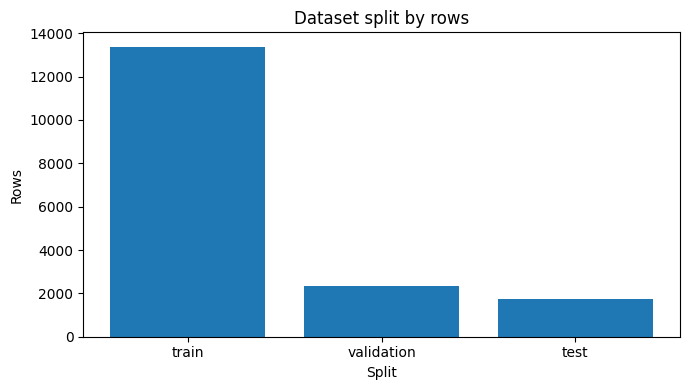

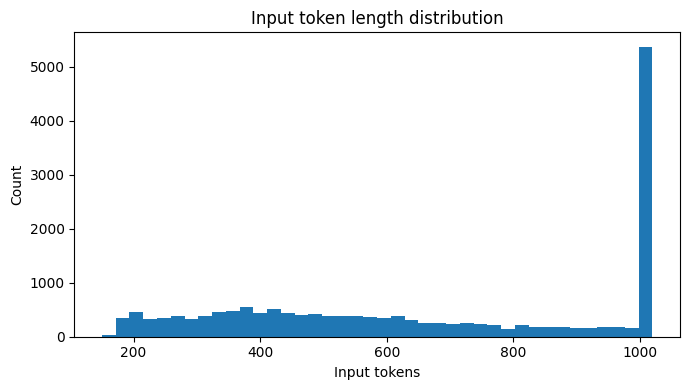

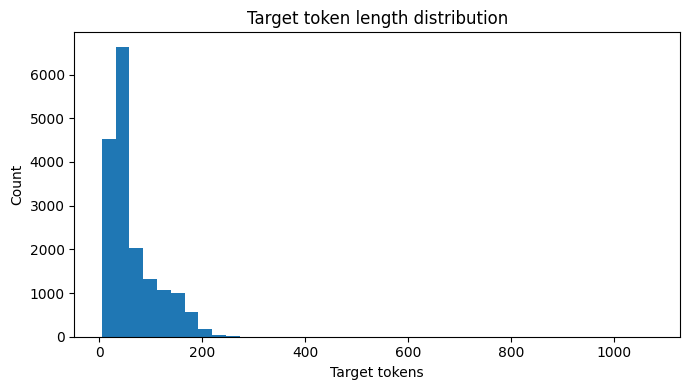

In [7]:
# visualize dataset split

plt.figure(figsize=(7, 4))
plt.bar(splitSummaryDf["split"], splitSummaryDf["rows"])
plt.title("Dataset split by rows")
plt.xlabel("Split")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(df["inputTokenLength"], bins=40)
plt.title("Input token length distribution")
plt.xlabel("Input tokens")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(df["targetTokenLength"], bins=40)
plt.title("Target token length distribution")
plt.xlabel("Target tokens")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [8]:
# create dataset objects

datasetColumns = [
    "rowId",
    "instruction",
    "question",
    "context_text",
    "answer",
    "targetText",
    "inputText",
    "ref_link",
    "groupKey"
]

trainRawDataset = Dataset.from_pandas(trainDf[datasetColumns], preserve_index=False)
validationRawDataset = Dataset.from_pandas(validationDf[datasetColumns], preserve_index=False)
testRawDataset = Dataset.from_pandas(testDf[datasetColumns], preserve_index=False)

print("train dataset:", len(trainRawDataset))
print("validation dataset:", len(validationRawDataset))
print("test dataset:", len(testRawDataset))

train dataset: 13376
validation dataset: 2320
test dataset: 1750


In [9]:
# preprocess datasets

def preprocess(batch):
    modelInputs = tokenizer(
        batch["inputText"],
        max_length=maxInputLength,
        truncation=True,
        padding=False
    )

    labels = tokenizer(
        text_target=batch["targetText"],
        max_length=maxTargetLength,
        truncation=True,
        padding=False
    )

    modelInputs["labels"] = labels["input_ids"]
    return modelInputs

trainDataset = trainRawDataset.map(
    preprocess,
    batched=True,
    remove_columns=trainRawDataset.column_names
)

validationDataset = validationRawDataset.map(
    preprocess,
    batched=True,
    remove_columns=validationRawDataset.column_names
)

testDataset = testRawDataset.map(
    preprocess,
    batched=True,
    remove_columns=testRawDataset.column_names
)

print("processed train rows:", len(trainDataset))
print("processed validation rows:", len(validationDataset))
print("processed test rows:", len(testDataset))

Map:   0%|          | 0/13376 [00:00<?, ? examples/s]

Map:   0%|          | 0/2320 [00:00<?, ? examples/s]

Map:   0%|          | 0/1750 [00:00<?, ? examples/s]

processed train rows: 13376
processed validation rows: 2320
processed test rows: 1750


## Encoder-decoder architecture

The model uses a transformer encoder-decoder architecture. The encoder processes the Arabic input sequence. The decoder generates the answer token by token while attending to the encoder hidden states through cross-attention.

In [ ]:
# load model and inspect architecture

def loadModel(modelPathOrName=baseModelName):
    loadedModel = AutoModelForSeq2SeqLM.from_pretrained(
        modelPathOrName,
        use_safetensors=False,
        torch_dtype=torch.bfloat16 if torch.cuda.is_available() else torch.float32
    )

    loadedModel.config.use_cache = False
    return loadedModel.to(device)

model = loadModel(baseModelName)

print("model:", baseModelName)
print("is encoder-decoder:", model.config.is_encoder_decoder)
print("encoder class:", model.get_encoder().__class__.__name__)
print("decoder class:", model.get_decoder().__class__.__name__)
print("hidden size:", model.config.d_model)
print("vocabulary size:", model.config.vocab_size)
print("parameters:", sum(parameter.numel() for parameter in model.parameters()))

In [12]:
# metric-only utilities with Arabic-normalized evaluation

import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import torch
import sacrebleu

from bert_score import score as bertScore
from sentence_transformers import SentenceTransformer, util

device = "cuda" if torch.cuda.is_available() else "cpu"

semanticMetricModel = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    device=device
)

def normalizeText(text):
    text = str(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def cleanGeneratedText(text):
    text = normalizeText(text)
    text = re.sub(r"<extra_id_\d+>", " ", text)
    text = re.sub(r"^(الإجابة|الجواب)\s*[:：]\s*", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def cleanReference(text):
    text = str(text)
    text = re.sub(r"\s*هذا الجواب مستند إلى المصدر التالي:\s*\S+\s*$", "", text).strip()
    text = re.sub(r"\s+", " ", text).strip()
    return text

def normalizeArabicText(text):
    text = str(text)
    text = unicodedata.normalize("NFKC", text)

    text = re.sub(r"[\u064B-\u065F\u0670]", "", text)

    text = re.sub(r"[إأآٱا]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"ة", "ه", text)
    text = re.sub(r"ؤ", "و", text)
    text = re.sub(r"ئ", "ي", text)

    text = re.sub(r"گ", "ك", text)
    text = re.sub(r"چ", "ج", text)
    text = re.sub(r"پ", "ب", text)
    text = re.sub(r"ڤ", "ف", text)

    text = re.sub(r"ـ", "", text)

    text = re.sub(r"[“”\"'`´،؛؟!.,:()\[\]{}<>«»]", " ", text)
    text = re.sub(r"[^\w\s\u0600-\u06FF]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

def tokenizeArabic(text):
    return normalizeArabicText(text).split()

def lcsLength(tokensA, tokensB):
    rows = len(tokensA) + 1
    cols = len(tokensB) + 1
    dp = [[0] * cols for _ in range(rows)]

    for i in range(1, rows):
        for j in range(1, cols):
            if tokensA[i - 1] == tokensB[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])

    return dp[-1][-1]

def rougeLArabic(prediction, reference):
    predTokens = tokenizeArabic(prediction)
    refTokens = tokenizeArabic(reference)

    if len(predTokens) == 0 or len(refTokens) == 0:
        return {"precision": 0.0, "recall": 0.0, "f1": 0.0}

    lcs = lcsLength(predTokens, refTokens)

    precision = lcs / len(predTokens)
    recall = lcs / len(refTokens)
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)

    return {"precision": precision, "recall": recall, "f1": f1}

def getSkipBigrams(tokens, maxSkip=4):
    bigrams = set()

    for i in range(len(tokens)):
        for skip in range(1, maxSkip + 2):
            j = i + skip

            if j < len(tokens):
                bigrams.add((tokens[i], tokens[j]))

    return bigrams

def rougeSArabic(prediction, reference, maxSkip=4):
    predTokens = tokenizeArabic(prediction)
    refTokens = tokenizeArabic(reference)

    predBigrams = getSkipBigrams(predTokens, maxSkip=maxSkip)
    refBigrams = getSkipBigrams(refTokens, maxSkip=maxSkip)

    if not predBigrams or not refBigrams:
        return {"precision": 0.0, "recall": 0.0, "f1": 0.0}

    overlap = len(predBigrams & refBigrams)
    precision = overlap / len(predBigrams)
    recall = overlap / len(refBigrams)
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)

    return {"precision": precision, "recall": recall, "f1": f1}

def tokenF1Arabic(prediction, reference):
    predTokens = tokenizeArabic(prediction)
    refTokens = tokenizeArabic(reference)

    if len(predTokens) == 0 or len(refTokens) == 0:
        return 0.0

    overlap = sum((Counter(predTokens) & Counter(refTokens)).values())

    if overlap == 0:
        return 0.0

    precision = overlap / len(predTokens)
    recall = overlap / len(refTokens)

    return 2 * precision * recall / (precision + recall)

def exactMatchArabic(prediction, reference):
    return int(normalizeArabicText(prediction) == normalizeArabicText(reference))

def containsNoAnswer(text):
    normalized = normalizeArabicText(text)
    return int("لا تتوفر معلومات كافيه" in normalized or "لا توجد معلومات كافيه" in normalized)

def computeMetricsHonest(predictions, references):
    predictions = [cleanGeneratedText(x) for x in predictions]
    references = [cleanReference(x) for x in references]

    bleu = sacrebleu.corpus_bleu(predictions, [references]).score
    chrf = sacrebleu.corpus_chrf(predictions, [references]).score

    bertPrecision, bertRecall, bertF1 = bertScore(
        predictions,
        references,
        lang="ar",
        verbose=False,
        rescale_with_baseline=False,
        device=device
    )

    predEmbeddings = semanticMetricModel.encode(
        predictions,
        convert_to_tensor=True,
        show_progress_bar=False
    )

    refEmbeddings = semanticMetricModel.encode(
        references,
        convert_to_tensor=True,
        show_progress_bar=False
    )

    semanticSimilarities = util.cos_sim(predEmbeddings, refEmbeddings).diagonal()

    arabicRougeLResults = [
        rougeLArabic(prediction, reference)
        for prediction, reference in zip(predictions, references)
    ]

    arabicRougeSResults = [
        rougeSArabic(prediction, reference)
        for prediction, reference in zip(predictions, references)
    ]

    arabicTokenF1Scores = [
        tokenF1Arabic(prediction, reference)
        for prediction, reference in zip(predictions, references)
    ]

    exactMatchScores = [
        exactMatchArabic(prediction, reference)
        for prediction, reference in zip(predictions, references)
    ]

    noAnswerScores = [
        containsNoAnswer(prediction)
        for prediction in predictions
    ]

    predictionLengths = [len(tokenizeArabic(prediction)) for prediction in predictions]
    referenceLengths = [len(tokenizeArabic(reference)) for reference in references]

    metrics = {
        "BLEU": bleu,
        "chrF": chrf,
        "BERTScore_Precision": float(bertPrecision.mean()),
        "BERTScore_Recall": float(bertRecall.mean()),
        "BERTScore_F1": float(bertF1.mean()),
        "Semantic_Textual_Similarity": float(semanticSimilarities.mean()),

        "Arabic_ROUGE_L_Precision": float(np.mean([item["precision"] for item in arabicRougeLResults])),
        "Arabic_ROUGE_L_Recall": float(np.mean([item["recall"] for item in arabicRougeLResults])),
        "Arabic_ROUGE_L_F1": float(np.mean([item["f1"] for item in arabicRougeLResults])),

        "Arabic_ROUGE_S_Precision": float(np.mean([item["precision"] for item in arabicRougeSResults])),
        "Arabic_ROUGE_S_Recall": float(np.mean([item["recall"] for item in arabicRougeSResults])),
        "Arabic_ROUGE_S_F1": float(np.mean([item["f1"] for item in arabicRougeSResults])),

        "Arabic_Token_F1": float(np.mean(arabicTokenF1Scores)),
        "Arabic_Exact_Match": float(np.mean(exactMatchScores)),
        "No_Answer_Rate": float(np.mean(noAnswerScores)),
        "Average_Prediction_Length": float(np.mean(predictionLengths)),
        "Average_Reference_Length": float(np.mean(referenceLengths)),
    }

    details = pd.DataFrame({
        "referenceAnswer": references,
        "prediction": predictions,
        "semanticSimilarity": semanticSimilarities.detach().cpu().numpy(),
        "arabicRougeL_F1": [item["f1"] for item in arabicRougeLResults],
        "arabicRougeS_F1": [item["f1"] for item in arabicRougeSResults],
        "arabicTokenF1": arabicTokenF1Scores,
        "arabicExactMatch": exactMatchScores,
        "noAnswer": noAnswerScores,
        "predictionLength": predictionLengths,
        "referenceLength": referenceLengths
    })

    return metrics, details

/home/rubaegb/my_venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [13]:
# prepare final test inputs and references

testInputTexts = [normalizeText(x) for x in testRawDataset["inputText"]]
testReferences = [normalizeText(x) for x in testRawDataset["targetText"]]

print("test inputs:", len(testInputTexts))
print("test references:", len(testReferences))
print("test input preview:")
print(testInputTexts[0][:800])
print("\ntest reference:")
print(testReferences[0])

test inputs: 1750
test references: 1750
test input preview:
أجب عن السؤال التالي باللغة العربية اعتمادًا على السياق المرفق فقط. إذا لم تكن الإجابة موجودة في السياق، قل: لا تتوفر معلومات كافية. التعليمة: أنت راوٍ وحارس للذاكرة الجماعية الفلسطينية، متخصص في روايات القرى والمدن الفلسطينيه. أجب بناءً على الشهادات الشفهية والمصادر المحلية الموثّقة، مع الحفاظ على أصالة السياق الإنساني. السؤال: ماذا فعل المستوطنون في واقعة المستوطنون يواصلون أعمال العربدة جنوب جنين؟ السياق: واصل المستوطنون المتطرفون الليلة الماضية أعمال العربدة في موقع مستوطنة "حومش" المخلاة جنوب مدينة جنين بالضفة المحتلة، واعتدوا على المواطنين في هجمة متواصلة منذ مساء أمس. وقالت مصادر محلية إن المستوطنين الذين اقتحموا المنطقة مساء أمس ظلوا فيها حتى وقت مبكر من فجر اليوم تحت حراسة مشددة من جيش الاحتلال، ويأتون إلى هذه المنطقة في كل عيد يهودي. وأشارت المصادر إلى أن عددا من المركبات تضررت و

test reference:
واصل المستوطنون المتطرفون الليلة الماضية أعمال العربدة في موقع مستوطنة "حومش" المخلاة جنوب مدينة جنين بالضفة المحتلة،


## Baseline evaluation

The baseline is the pretrained `google/mt5-large` model evaluated on the held-out test set before task-specific fine-tuning.

In [14]:
# # run or load baseline predictions

# baselinePredictionsPath = resultsDir / "baseline_test_predictions.csv"
# baselineMetricsPath = resultsDir / "baseline_test_metrics.csv"

# if runBaselineEvaluation:
#     baselineModel = loadModel(baseModelName)

#     baselinePredictions = generateAnswersCheckpointed(
#         baselineModel,
#         testInputTexts,
#         outputCsvPath=baselinePredictionsPath,
#         batchSize=evalBatchSize,
#         maxNewTokens=maxTargetLength,
#         numBeams=generationNumBeams,
#         forceRegenerate=forceRegenerateBaselinePredictions
#     )

#     cleanedBaselinePredictions = [
#         cleanGeneratedText(prediction)
#         for prediction in baselinePredictions
#     ]

#     baselineMetrics, baselineSemanticSimilarities, baselineRougeLResults, baselineRougeSResults = computeMetrics(
#         cleanedBaselinePredictions,
#         testReferences
#     )

#     baselineMetricsDf = pd.DataFrame([baselineMetrics])
#     baselineMetricsDf.to_csv(baselineMetricsPath, index=False, encoding="utf-8-sig")

#     baselineResultsDf = pd.DataFrame({
#         "inputText": testInputTexts,
#         "referenceAnswer": testReferences,
#         "baselinePrediction": baselinePredictions,
#         "cleanedBaselinePrediction": cleanedBaselinePredictions,
#         "semanticSimilarity": baselineSemanticSimilarities.cpu().numpy(),
#         "rougeL_F1": [item.fmeasure for item in baselineRougeLResults],
#         "rougeS_F1": [item["f1"] for item in baselineRougeSResults]
#     })

#     baselineResultsDf.to_csv(
#         resultsDir / "baseline_test_prediction_details.csv",
#         index=False,
#         encoding="utf-8-sig"
#     )

#     del baselineModel
#     torch.cuda.empty_cache()
#     gc.collect()
# else:
#     baselineMetricsDf = pd.read_csv(baselineMetricsPath)
#     baselineMetrics = baselineMetricsDf.iloc[0].to_dict()

# print("baseline metrics")
# print(pd.DataFrame([baselineMetrics]).T)

In [16]:
# metric-only baseline evaluation from saved predictions

baselineDetailsPath = resultsDir / "baseline_test_prediction_details.csv"

baselineDetailsDf = pd.read_csv(baselineDetailsPath).fillna("")
print(baselineDetailsDf.columns.tolist())

predictionColumn = "cleanedBaselinePrediction"
#referenceColumn = "referenceAnswer"

baselinePredictions = baselineDetailsDf[predictionColumn].astype(str).tolist()
baselineReferences = baselineDetailsDf[referenceColumn].astype(str).tolist()

baselineMetrics, baselineMetricDetailsDf = computeMetricsHonest(
    baselinePredictions,
    baselineReferences
)

baselineMetrics["system"] = "baseline_pretrained_mt5_large"
baselineMetrics["contextType"] = "gold_full_context"
baselineMetrics["Max_Input_Tokens"] = maxInputLength
baselineMetrics["Max_New_Tokens"] = maxTargetLength

baselineMetricsDf = pd.DataFrame([baselineMetrics])

for col in ["inputText", "referenceAnswer", "baselinePrediction", "cleanedBaselinePrediction"]:
    if col in baselineDetailsDf.columns:
        if col in baselineMetricDetailsDf.columns:
            baselineMetricDetailsDf[col] = baselineDetailsDf[col].tolist()
        else:
            baselineMetricDetailsDf.insert(0, col, baselineDetailsDf[col].tolist())
            
baselineMetricsDf.to_csv(
    metricOnlyDir / "baseline_test_metrics_corrected.csv",
    index=False,
    encoding="utf-8-sig"
)

baselineMetricDetailsDf.to_csv(
    metricOnlyDir / "baseline_test_prediction_details_corrected_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("corrected baseline metrics")
print(baselineMetricsDf.T)

## Fine-tuning

The model is fine-tuned on the training split. The validation split is used for monitoring and checkpoint selection. The test split remains held out until final evaluation.

In [17]:
# configure trainable parameters

model = loadModel(baseModelName)
model.config.use_cache = False

if freezeEncoder:
    for parameter in model.get_encoder().parameters():
        parameter.requires_grad = False

trainableParams = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
allParams = sum(parameter.numel() for parameter in model.parameters())

print("freeze encoder:", freezeEncoder)
print("trainable parameters:", trainableParams)
print("all parameters:", allParams)
print("trainable percent:", round(100 * trainableParams / allParams, 4))

freeze encoder: True
trainable parameters: 665134592
all parameters: 1229581312
trainable percent: 54.0944


In [26]:
# prepare trainer

dataCollator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    label_pad_token_id=-100
)

trainingArgs = Seq2SeqTrainingArguments(
    output_dir=outputDir,

    eval_strategy="epoch",
    save_strategy="epoch",
    
    eval_steps=evalSteps,
    save_steps=saveSteps,
    save_total_limit=saveTotalLimit,

    learning_rate=learningRate,
    per_device_train_batch_size=trainBatchSize,
    per_device_eval_batch_size=evalBatchSize,
    gradient_accumulation_steps=gradientAccumulationSteps,
    weight_decay=0.01,

    num_train_epochs=numTrainEpochs,

    predict_with_generate=True,
    generation_max_length=maxTargetLength,

    logging_steps=loggingSteps,
    report_to="none",

    fp16=False,
    bf16=torch.cuda.is_available(),

    gradient_checkpointing=False if freezeEncoder else True,
    max_grad_norm=1.0,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    save_safetensors=False,
    
    warmup_ratio=0.05,
    lr_scheduler_type="constant_with_warmup",
        
    seed=seed,
    data_seed=seed
)

if "trainer" in locals():
    del trainer

torch.cuda.empty_cache()
gc.collect()

trainer = Seq2SeqTrainer(
    model=model,
    args=trainingArgs,
    train_dataset=trainDataset,
    eval_dataset=validationDataset,
    data_collator=dataCollator
)

expectedSteps = math.ceil(len(trainDataset) / trainBatchSize / gradientAccumulationSteps) * numTrainEpochs

print("expected optimizer steps:", expectedSteps)
print("train batch size:", trainer.args.per_device_train_batch_size)
print("eval batch size:", trainer.args.per_device_eval_batch_size)
print("gradient accumulation:", trainer.args.gradient_accumulation_steps)
print("validation rows:", len(validationDataset))

expected optimizer steps: 4180
train batch size: 2
eval batch size: 2
gradient accumulation: 8
validation rows: 2320


In [27]:
# run fine-tuning

trainOutput = trainer.train()

print("training complete")
print(trainOutput)

Epoch,Training Loss,Validation Loss
1,1.721100,1.678406
2,1.553200,1.617354
3,1.509200,1.584192
4,1.510900,1.563251
5,1.506300,1.545151


training complete
TrainOutput(global_step=4180, training_loss=3.1103366426303625, metrics={'train_runtime': 8581.1626, 'train_samples_per_second': 7.794, 'train_steps_per_second': 0.487, 'total_flos': 3.231339507591168e+17, 'train_loss': 3.1103366426303625, 'epoch': 5.0})


In [28]:
# save fine-tuned model

trainer.save_model(outputDir)
tokenizer.save_pretrained(outputDir)

model = trainer.model
model.eval()

print("saved fine-tuned model to:", outputDir)

saved fine-tuned model to: ./outputs/google/mt5-large-full-context-validated


     step    loss  eval_loss  learning_rate     epoch
153  3750  1.5343        NaN        0.00005  4.485646
154  3775  1.5589        NaN        0.00005  4.515550
155  3800  1.4774        NaN        0.00005  4.545455
156  3825  1.4696        NaN        0.00005  4.575359
157  3850  1.5422        NaN        0.00005  4.605263
158  3875  1.5156        NaN        0.00005  4.635167
159  3900  1.5673        NaN        0.00005  4.665072
160  3925  1.5243        NaN        0.00005  4.694976
161  3950  1.5787        NaN        0.00005  4.724880
162  3975  1.5303        NaN        0.00005  4.754785
163  4000  1.5491        NaN        0.00005  4.784689
164  4025  1.4670        NaN        0.00005  4.814593
165  4050  1.5279        NaN        0.00005  4.844498
166  4075  1.5229        NaN        0.00005  4.874402
167  4100  1.5146        NaN        0.00005  4.904306
168  4125  1.4641        NaN        0.00005  4.934211
169  4150  1.5958        NaN        0.00005  4.964115
170  4175  1.5063        NaN

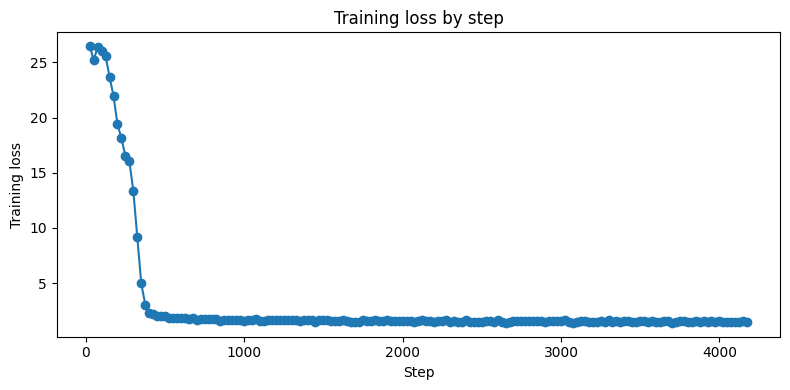

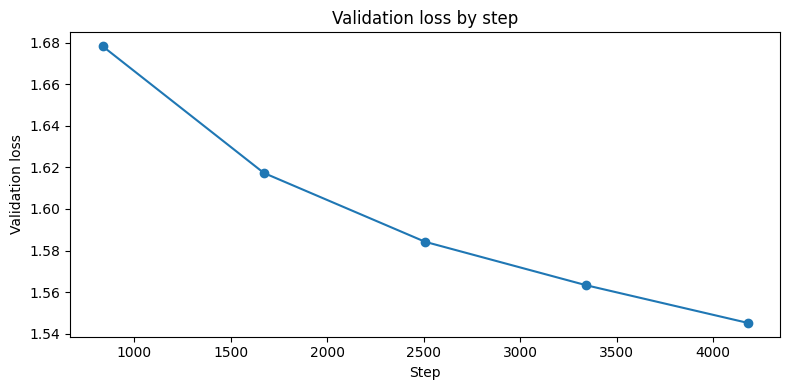

In [29]:
# export and visualize training logs

trainingLogDf = pd.DataFrame(trainer.state.log_history)
trainingLogDf.to_csv(resultsDir / "training_log_history.csv", index=False, encoding="utf-8-sig")

displayColumns = [column for column in ["step", "loss", "eval_loss", "learning_rate", "epoch"] if column in trainingLogDf.columns]
print(trainingLogDf[displayColumns].tail(20))

if "loss" in trainingLogDf.columns:
    trainLossDf = trainingLogDf.dropna(subset=["loss"])

    plt.figure(figsize=(8, 4))
    plt.plot(trainLossDf["step"], trainLossDf["loss"], marker="o")
    plt.title("Training loss by step")
    plt.xlabel("Step")
    plt.ylabel("Training loss")
    plt.tight_layout()
    plt.show()

if "eval_loss" in trainingLogDf.columns:
    evalLossDf = trainingLogDf.dropna(subset=["eval_loss"])

    plt.figure(figsize=(8, 4))
    plt.plot(evalLossDf["step"], evalLossDf["eval_loss"], marker="o")
    plt.title("Validation loss by step")
    plt.xlabel("Step")
    plt.ylabel("Validation loss")
    plt.tight_layout()
    plt.show()

In [ ]:
# please note the figure up in the x-axis the parameter is Epoch not step ... it is epoch based 

## Fine-tuned test evaluation

The final evaluation uses the held-out test split only. The same test inputs and references are used for baseline and fine-tuned systems.

In [33]:
def getExtraIdBadWords(tokenizer):
    badWords = []

    for index in range(100):
        token = f"<extra_id_{index}>"
        tokenId = tokenizer.convert_tokens_to_ids(token)

        if tokenId is not None and tokenId != tokenizer.unk_token_id:
            badWords.append([tokenId])

    return badWords


extraIdBadWords = getExtraIdBadWords(tokenizer)


@torch.no_grad()
def generateAnswersCheckpointed(
    model,
    inputTexts,
    outputCsvPath,
    batchSize=evalBatchSize,
    maxNewTokens=maxTargetLength,
    numBeams=generationNumBeams,
    forceRegenerate=False
):
    outputCsvPath = Path(outputCsvPath)
    outputCsvPath.parent.mkdir(parents=True, exist_ok=True)

    if outputCsvPath.exists() and not forceRegenerate:
        existingDf = pd.read_csv(outputCsvPath).fillna("")

        if "rowIndex" in existingDf.columns:
            existingDf = (
                existingDf
                .sort_values("rowIndex")
                .drop_duplicates("rowIndex")
                .reset_index(drop=True)
            )

            if len(existingDf) == len(inputTexts):
                print("loading complete cached predictions:", outputCsvPath)
                return existingDf["prediction"].astype(str).tolist()

            rows = existingDf.to_dict("records")
            startIndex = len(rows)
            print("resuming generation from row:", startIndex)
        else:
            rows = []
            startIndex = 0
            print("cached file has no rowIndex, regenerating from scratch")
    else:
        rows = []
        startIndex = 0
        print("starting generation from row:", startIndex)

    model.eval()

    for start in tqdm(range(startIndex, len(inputTexts), batchSize), desc="generating"):
        batchTexts = inputTexts[start:start + batchSize]

        inputs = tokenizer(
            batchTexts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=maxInputLength
        ).to(model.device)

        generationKwargs = {
            "max_new_tokens": maxNewTokens,
            "num_beams": numBeams,
            "early_stopping": True if numBeams > 1 else False,
            "no_repeat_ngram_size": 3,
        }

        if len(extraIdBadWords) > 0:
            generationKwargs["bad_words_ids"] = extraIdBadWords

        outputIds = model.generate(
            **inputs,
            **generationKwargs
        )

        predictions = tokenizer.batch_decode(
            outputIds,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=True
        )

        for offset, prediction in enumerate(predictions):
            rows.append({
                "rowIndex": start + offset,
                "prediction": prediction
            })

        pd.DataFrame(rows).to_csv(outputCsvPath, index=False, encoding="utf-8-sig")

    rowsDf = (
        pd.DataFrame(rows)
        .sort_values("rowIndex")
        .drop_duplicates("rowIndex")
        .reset_index(drop=True)
    )

    rowsDf.to_csv(outputCsvPath, index=False, encoding="utf-8-sig")

    return rowsDf["prediction"].astype(str).tolist()

In [34]:
fineTunedPredictionsPath = resultsDir / "fine_tuned_test_predictions.csv"

fineTunedPredictions = generateAnswersCheckpointed(
    model,
    testInputTexts,
    outputCsvPath=fineTunedPredictionsPath,
    batchSize=evalBatchSize,
    maxNewTokens=maxTargetLength,
    numBeams=generationNumBeams,
    forceRegenerate=forceRegenerateFineTunedPredictions
)

fineTunedMetrics, fineTunedMetricDetailsDf = computeMetricsHonest(
    fineTunedPredictions,
    testReferences
)

fineTunedMetrics["system"] = "fine_tuned_mt5_large"
fineTunedMetrics["contextType"] = "gold_full_context"
fineTunedMetrics["Max_Input_Tokens"] = maxInputLength
fineTunedMetrics["Max_New_Tokens"] = maxTargetLength

fineTunedMetricsDf = pd.DataFrame([fineTunedMetrics])

for col in ["inputText", "referenceAnswer", "prediction"]:
    if col in fineTunedMetricDetailsDf.columns:
        continue

fineTunedMetricDetailsDf.insert(0, "inputText", testInputTexts)
fineTunedMetricDetailsDf.insert(1, "fineTunedPredictionRaw", fineTunedPredictions)

fineTunedMetricsDf.to_csv(
    metricOnlyDir / "fine_tuned_test_metrics_corrected.csv",
    index=False,
    encoding="utf-8-sig"
)

fineTunedMetricDetailsDf.to_csv(
    metricOnlyDir / "fine_tuned_test_prediction_details_corrected_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("corrected fine-tuned metrics")
print(fineTunedMetricsDf.T)

starting generation from row: 0


generating: 100%|█████████████████████████████████████████████████████████████████████| 875/875 [47:06<00:00,  3.23s/it]
/home/rubaegb/my_venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


corrected fine-tuned metrics
                                                0
BLEU                                    10.323817
chrF                                    25.893206
BERTScore_Precision                      0.735285
BERTScore_Recall                         0.721154
BERTScore_F1                             0.726576
Semantic_Textual_Similarity               0.50815
Arabic_ROUGE_L_Precision                 0.256929
Arabic_ROUGE_L_Recall                    0.216061
Arabic_ROUGE_L_F1                        0.206192
Arabic_ROUGE_S_Precision                 0.132577
Arabic_ROUGE_S_Recall                    0.109827
Arabic_ROUGE_S_F1                        0.101354
Arabic_Token_F1                          0.223891
Arabic_Exact_Match                       0.000571
No_Answer_Rate                           0.003429
Average_Prediction_Length                  20.504
Average_Reference_Length                26.177714
system                       fine_tuned_mt5_large
contextType          

In [31]:
# # metric-only fine-tuned evaluation from saved predictions

# # fineTunedDetailsPath = resultsDir / "fine_tuned_test_prediction_details.csv"

# # fineTunedDetailsDf = pd.read_csv(fineTunedDetailsPath).fillna("")
# # print(fineTunedDetailsDf.columns.tolist())

# predictionColumn = "cleanedFineTunedPrediction"
# referenceColumn = "referenceAnswer"

# fineTunedPredictions = fineTunedDetailsDf[predictionColumn].astype(str).tolist()
# fineTunedReferences = fineTunedDetailsDf[referenceColumn].astype(str).tolist()

# fineTunedMetrics, fineTunedMetricDetailsDf = computeMetricsHonest(
#     fineTunedPredictions,
#     fineTunedReferences
# )

# fineTunedMetrics["system"] = "fine_tuned_mt5_large"
# fineTunedMetrics["contextType"] = "gold_full_context"
# fineTunedMetrics["Max_Input_Tokens"] = maxInputLength
# fineTunedMetrics["Max_New_Tokens"] = maxTargetLength

# fineTunedMetricsDf = pd.DataFrame([fineTunedMetrics])
        
# for col in ["inputText", "referenceAnswer", "baselinePrediction", "cleanedBaselinePrediction"]:
#     if col in baselineDetailsDf.columns:
#         if col in baselineMetricDetailsDf.columns:
#             baselineMetricDetailsDf[col] = baselineDetailsDf[col].tolist()
#         else:
#             baselineMetricDetailsDf.insert(0, col, baselineDetailsDf[col].tolist())

# fineTunedMetricsDf.to_csv(
#     metricOnlyDir / "fine_tuned_test_metrics_corrected.csv",
#     index=False,
#     encoding="utf-8-sig"
# )

# fineTunedMetricDetailsDf.to_csv(
#     metricOnlyDir / "fine_tuned_test_prediction_details_corrected_metrics.csv",
#     index=False,
#     encoding="utf-8-sig"
# )

# print("corrected fine-tuned metrics")
# print(fineTunedMetricsDf.T)

['inputText', 'referenceAnswer', 'fineTunedPrediction', 'cleanedFineTunedPrediction', 'semanticSimilarity', 'rougeL_F1', 'rougeS_F1']


/home/rubaegb/my_venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


NameError: name 'baselineMetricDetailsDf' is not defined

In [35]:
# corrected baseline vs fine-tuned comparison

comparisonDf = pd.concat(
    [baselineMetricsDf, fineTunedMetricsDf],
    ignore_index=True
)

metricsForImprovement = [
    "BLEU",
    "chrF",
    "BERTScore_F1",
    "Semantic_Textual_Similarity",
    "Arabic_ROUGE_L_F1",
    "Arabic_ROUGE_S_F1",
    "Arabic_Token_F1",
    "Arabic_Exact_Match"
]

baselineRow = comparisonDf[comparisonDf["system"] == "baseline_pretrained_mt5_large"].iloc[0]

for metric in metricsForImprovement:
    comparisonDf[f"{metric}_improvement_vs_baseline"] = comparisonDf[metric] - baselineRow[metric]

mainColumns = [
    "system",
    "contextType",
    "Max_Input_Tokens",
    "Max_New_Tokens",
    "BLEU",
    "chrF",
    "BERTScore_F1",
    "Semantic_Textual_Similarity",
    "Arabic_ROUGE_L_F1",
    "Arabic_ROUGE_S_F1",
    "Arabic_Token_F1",
    "Arabic_Exact_Match",
    "No_Answer_Rate",
    "Average_Prediction_Length",
    "Average_Reference_Length"
]

remainingColumns = [col for col in comparisonDf.columns if col not in mainColumns]
comparisonDf = comparisonDf[mainColumns + remainingColumns]

comparisonDf.to_csv(
    metricOnlyDir / "baseline_vs_fine_tuned_test_metrics_corrected.csv",
    index=False,
    encoding="utf-8-sig"
)

comparisonDf

NameError: name 'baselineMetricsDf' is not defined

In [36]:
# visualize comparative metrics

plotMetrics = [
    "BLEU",
    "chrF",
    "BERTScore_F1",
    "Semantic_Textual_Similarity",
    "Arabic_ROUGE_L_F1",
    "Arabic_ROUGE_S_F1"
]

plotDf = comparisonDf[["system"] + plotMetrics].set_index("system")

for metric in plotMetrics:
    plt.figure(figsize=(7, 4))
    plt.bar(plotDf.index, plotDf[metric])
    plt.title(f"{metric} comparison")
    plt.xlabel("System")
    plt.ylabel(metric)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

NameError: name 'comparisonDf' is not defined

In [37]:
# inspect sample predictions

sampleCount = min(10, len(fineTunedResultsDf))

sampleReviewDf = pd.DataFrame({
    "question": [text.split("السؤال:")[-1].split("السياق:")[0].strip() for text in testInputTexts[:sampleCount]],
    "reference": testReferences[:sampleCount],
#     "prediction": fineTunedPredictions[:sampleCount],
    "prediction": cleanedFineTunedPredictions[:sampleCount],
    "rougeL_F1": [item.fmeasure for item in fineTunedRougeLResults[:sampleCount]],
    "semanticSimilarity": fineTunedSemanticSimilarities[:sampleCount].detach().cpu().numpy()
})

sampleReviewDf.to_csv(
    resultsDir / "sample_prediction_review.csv",
    index=False,
    encoding="utf-8-sig"
)

sampleReviewDf

NameError: name 'fineTunedResultsDf' is not defined

## Result interpretation checklist

- Confirm that the model is encoder-decoder based.
- Confirm that fine-tuning uses the training split only.
- Confirm that validation loss is used for monitoring.
- Confirm that final metrics are reported on the test split only.
- Compare baseline and fine-tuned results using the same held-out test set.
- Review sample predictions for factual errors, incomplete answers, and unsupported generation.

In [38]:
# save run summary

runSummary = {
    "baseModelName": baseModelName,
    "outputDir": outputDir,
    "dataPath": dataPath,
    "trainRows": len(trainRawDataset),
    "validationRows": len(validationRawDataset),
    "testRows": len(testRawDataset),
    "maxInputLength": maxInputLength,
    "maxTargetLength": maxTargetLength,
    "learningRate": learningRate,
    "trainBatchSize": trainBatchSize,
    "evalBatchSize": evalBatchSize,
    "gradientAccumulationSteps": gradientAccumulationSteps,
    "numTrainEpochs": numTrainEpochs,
    "freezeEncoder": freezeEncoder,
    "generationNumBeams": generationNumBeams,
    "device": device,
    "torchVersion": torch.__version__
}

with open(resultsDir / "run_summary.json", "w", encoding="utf-8") as file:
    json.dump(runSummary, file, ensure_ascii=False, indent=2)

print(json.dumps(runSummary, ensure_ascii=False, indent=2))

{
  "baseModelName": "google/mt5-large",
  "outputDir": "./outputs/google/mt5-large-full-context-validated",
  "dataPath": "data_qa.csv",
  "trainRows": 13376,
  "validationRows": 2320,
  "testRows": 1750,
  "maxInputLength": 1024,
  "maxTargetLength": 256,
  "learningRate": 5e-05,
  "trainBatchSize": 2,
  "evalBatchSize": 2,
  "gradientAccumulationSteps": 8,
  "numTrainEpochs": 5,
  "freezeEncoder": true,
  "generationNumBeams": 1,
  "device": "cuda",
  "torchVersion": "2.5.1+cu121"
}
